# FactCheck Model Evaluation & Benchmark Comparison

### Evaluated Models:
1. **llm-semantic-router/Vela-1.0-Encoder-307M-FactCheck** (Size: 307M)
2. **kalyan-ks/Ammu-1.0-FactCheck-base** (Size: 150M)
3. **kalyan-ks/Ammu-1.0-FactCheck-small** (Size: 68M)
4. **kalyan-ks/Ammu-1.0-FactCheck-tiny** (Size: 33M)
5. **kalyan-ks/Ammu-1.0-FactCheck-nano** (Size: 17M)

### Key Objectives:
- Compute category-wise **Macro-F1 score** across difficulty tiers (**Easy**, **Medium**, **Hard**) and **Overall**.


## 1. Install & Verify Dependencies
Run this cell in your Colab runtime (via VS Code or Web UI) to ensure all required libraries are installed.


In [1]:
# Install necessary dependencies
!pip install -q uv
!uv pip install --system transformers datasets evaluate scikit-learn pandas accelerate tabulate


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.8/17.8 MB 129.1 MB/s eta 0:00:0000:010:01
Using Python 3.13.15 environment at: /usr
Resolved 83 packages in 365ms                                        
Prepared 1 package in 6ms                                                
Installed 1 package in 3ms                                  
 + evaluate==0.4.6


## 2. Environment Setup & Google Drive Mount
Mount Google Drive to access the curated dataset splits (`train.csv`, `val.csv`, `test.csv`).


In [2]:
import os
import sys
import torch
import numpy as np
import pandas as pd
from datasets import load_dataset
from sklearn.metrics import f1_score, accuracy_score, classification_report
from transformers import pipeline
from tqdm.auto import tqdm

# Check runtime environment and hardware acceleration
device = 0 if torch.cuda.is_available() else -1
device_name = "CUDA (GPU)" if torch.cuda.is_available() else "CPU"
print(f"Active Device: {device_name}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

# Mount Google Drive if running in Google Colab environment
try:
    from google.colab import drive
    drive.mount("/content/drive")
    print("Google Drive mounted successfully.")
except ImportError:
    print("Running outside Google Colab (Local or Remote Kernel). Skipping drive.mount().")


Mounted at /content/drive
Google Drive mounted successfully.


## 3. Load & Inspect Curated Dataset
We load the curated splits using Hugging Face `load_dataset` directly from the Google Drive storage directory.


In [3]:
# Google Drive directory containing curated dataset splits
folder_path = "/content/drive/MyDrive/Kalyan KS/Learning/Preparation Notes/Projects/Fact Check Need Classifier/fact_check_curated_output/"

# Data files mapping
data_files = {
    "train": folder_path + "train.csv",
    "validation": folder_path + "val.csv",
    "test": folder_path + "test.csv",
}

# Verify file presence before loading
for split_name, file_path in data_files.items():
    if os.path.exists(file_path):
        print(f"Found {split_name} split: {file_path}")
    else:
        print(f"[Notice] File path check: {file_path}")

# Load dataset from CSV files
dataset = load_dataset("csv", data_files=data_files)

print("" + "=" * 80)
print("DATASET OVERVIEW:")
print("=" * 80)
print(dataset)


Found train split: /content/drive/MyDrive/Kalyan KS/Learning/Preparation Notes/Projects/Fact Check Need Classifier/fact_check_curated_output/train.csv
Found validation split: /content/drive/MyDrive/Kalyan KS/Learning/Preparation Notes/Projects/Fact Check Need Classifier/fact_check_curated_output/val.csv
Found test split: /content/drive/MyDrive/Kalyan KS/Learning/Preparation Notes/Projects/Fact Check Need Classifier/fact_check_curated_output/test.csv


Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DATASET OVERVIEW:
DatasetDict({
    train: Dataset({
        features: ['domain_group', 'topic', 'embedded_factual_topic', 'difficulty_profile', 'prompt_type', 'prompt_length', 'user_type', 'linguistic_register', 'tone', 'label', 'prompt_structure', 'difficulty_tier', 'difficulty_nuance', 'prompt_length_and_structure', 'length_adherence_rule', 'user_prompt', 'quality_judge', 'composite_score', 'composite_score_100', 'score_label_correctness', 'score_prompt_naturalness', 'score_taxonomy_adherence', 'score_training_signal', 'quality_gate_status', 'id'],
        num_rows: 21066
    })
    validation: Dataset({
        features: ['domain_group', 'topic', 'embedded_factual_topic', 'difficulty_profile', 'prompt_type', 'prompt_length', 'user_type', 'linguistic_register', 'tone', 'label', 'prompt_structure', 'difficulty_tier', 'difficulty_nuance', 'prompt_length_and_structure', 'length_adherence_rule', 'user_prompt', 'quality_judge', 'composite_score', 'composite_score_100', 'score_label_corre

## 4. Test Set Inspection & Data Preparation
Convert test partition into a pandas DataFrame and verify the distribution of `label` and `difficulty_tier`.


In [4]:
# Convert test set to DataFrame for stratified slicing and evaluation
test_df = pd.DataFrame(dataset["test"])

print(f"Total Test Samples: {len(test_df):,}")
print("Difficulty Tier Distribution in Test Set:")
print(test_df["difficulty_tier"].value_counts())

print("Label Distribution in Test Set:")
print(test_df["label"].value_counts())

print("Cross-Tabulation (Label vs Difficulty Tier):")
display(pd.crosstab(test_df["label"], test_df["difficulty_tier"], margins=True))


Total Test Samples: 4,214
Difficulty Tier Distribution in Test Set:
difficulty_tier
Hard      1700
Medium    1688
Easy       826
Name: count, dtype: int64
Label Distribution in Test Set:
label
FACT_CHECK_NEEDED       2107
NO_FACT_CHECK_NEEDED    2107
Name: count, dtype: int64
Cross-Tabulation (Label vs Difficulty Tier):


difficulty_tier,Easy,Hard,Medium,All
label,,,,
FACT_CHECK_NEEDED,406,854,847,2107
NO_FACT_CHECK_NEEDED,420,846,841,2107
All,826,1700,1688,4214


## 5. Model Catalog & Pipeline Evaluation Function
We leverage Hugging Face's `pipeline("text-classification", ...)` to provide a clean and compact inference abstraction.
Sequence truncation is kept as `truncation=False` because all evaluated FactCheck models natively support sequences of up to 8k tokens.


In [5]:
# Define the models to evaluate
models_to_eval = [
    {
        "name": "llm-semantic-router/Vela-1.0-Encoder-307M-FactCheck",
        "size": "307M",
        "display_name": "Vela-1.0-Encoder-FactCheck"
    },
    {
        "name": "kalyan-ks/Ammu-1.0-FactCheck-base",
        "size": "150M",
        "display_name": "Ammu-1.0-FactCheck-base"
    },
    {
        "name": "kalyan-ks/Ammu-1.0-FactCheck-small",
        "size": "68M",
        "display_name": "Ammu-1.0-FactCheck-small"
    },
    {
        "name": "kalyan-ks/Ammu-1.0-FactCheck-tiny",
        "size": "33M",
        "display_name": "Ammu-1.0-FactCheck-tiny"
    },
    {
        "name": "kalyan-ks/Ammu-1.0-FactCheck-nano",
        "size": "17M",
        "display_name": "Ammu-1.0-FactCheck-nano"
    }
]

def evaluate_model_pipeline(
    model_id: str,
    texts: list,
    batch_size: int = 64,
    device: int = 0 if torch.cuda.is_available() else -1
) -> list:
    """Evaluates a text classification model on a list of texts using Hugging Face pipeline."""
    print(f"Loading pipeline for: {model_id} (device={device}) ...")
    
    classifier = pipeline(
        "text-classification",
        model=model_id,
        device=device
    )

    print(f"Running inference on {len(texts):,} samples (batch_size={batch_size})...")
    outputs = classifier(texts, batch_size=batch_size)
    
    # Extract the predicted top label string directly
    predictions = [out["label"] for out in outputs]

    # Clean up GPU memory
    del classifier
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return predictions


## 6. Run Evaluation Across All Models
Infer predictions for each model on the holdout test set using the pipeline and store the resulting predictions in `test_df`.


In [6]:
test_texts = test_df["user_prompt"].tolist()

# Dictionary to store predictions for each model
predictions_dict = {}

for model_info in models_to_eval:
    m_name = model_info["name"]
    print("\n" + "=" * 90)
    print(f"Benchmarking: {m_name} (Size: {model_info['size']})")
    print("=" * 90)
    
    preds = evaluate_model_pipeline(
        model_id=m_name,
        texts=test_texts,
        batch_size=64 if torch.cuda.is_available() else 16,
        device=0 if torch.cuda.is_available() else -1
    )
    
    predictions_dict[m_name] = preds
    # Add predictions column into DataFrame
    col_name = f"pred_{model_info['display_name']}"
    test_df[col_name] = preds

print("\nInference completed for all models.")



Benchmarking: llm-semantic-router/Vela-1.0-Encoder-307M-FactCheck (Size: 307M)
Loading pipeline for: llm-semantic-router/Vela-1.0-Encoder-307M-FactCheck (device=0) ...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.65k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.23GB            

model.safetensors: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/48 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/488 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.58M [00:00<?, ?B/s]

Running inference on 4,214 samples (batch_size=64)...

Inference completed for all models.


## 7. Compute Macro-F1 Metric (Category-wise & Overall)
We compute:
- **Easy Macro-F1**: Evaluates performance on straightforward factual checks.
- **Medium Macro-F1**: Evaluates performance on moderately nuanced claims.
- **Hard Macro-F1**: Evaluates performance on ambiguous, multi-step, or adversarial queries.
- **Overall Macro-F1**: Overall macro-averaged F1 across the entire holdout test dataset.


In [7]:
results_list = []

true_labels = test_df["label"].tolist()

for model_info in models_to_eval:
    m_name = model_info["name"]
    m_display = model_info["display_name"]
    m_size = model_info["size"]
    pred_labels = predictions_dict[m_name]
    
    # Calculate overall metrics
    overall_f1 = f1_score(true_labels, pred_labels, average="macro")
    overall_acc = accuracy_score(true_labels, pred_labels)
    
    # Category-wise metrics: Easy, Medium, Hard
    tier_f1_scores = {}
    for tier in ["Easy", "Medium", "Hard"]:
        tier_mask = (test_df["difficulty_tier"] == tier)
        tier_true = test_df.loc[tier_mask, "label"].tolist()
        tier_pred = [pred_labels[idx] for idx in test_df.index[tier_mask]]
        
        tier_f1 = f1_score(tier_true, tier_pred, average="macro")
        tier_f1_scores[tier] = tier_f1
    
    results_list.append({
        "Model": m_name,
        "Size": m_size,
        "Easy": round(tier_f1_scores["Easy"] * 100, 2),
        "Medium": round(tier_f1_scores["Medium"] * 100, 2),
        "Hard": round(tier_f1_scores["Hard"] * 100, 2),
        "Overall": round(overall_f1 * 100, 2)
    })

# Convert to DataFrame
results_df = pd.DataFrame(results_list)


## 8. Benchmark Results Summary Table
Display the performance comparison with columns: `Model`, `Size`, `Easy`, `Medium`, `Hard`, `Overall`.


In [8]:
print("=" * 95)
print("FACT-CHECK CLASSIFIER BENCHMARK RESULTS (Macro-F1 %)")
print("=" * 95)
display(results_df)

# Print markdown format for easy copying to reports/documentation
print("\nMarkdown Table Format:")
try:
    print(results_df.to_markdown(index=False))
except Exception:
    print(results_df.to_string(index=False))


FACT-CHECK CLASSIFIER BENCHMARK RESULTS (Macro-F1 %)


,Model,Size,Easy,Medium,Hard,Overall
0,llm-semantic-router/Vela-1.0-Encoder-307M-Fact...,307M,77.72,70.64,64.15,69.42
1,kalyan-ks/Ammu-1.0-FactCheck-base,150M,98.91,96.74,95.23,96.56
2,kalyan-ks/Ammu-1.0-FactCheck-small,68M,98.55,95.97,95.11,96.13
3,kalyan-ks/Ammu-1.0-FactCheck-tiny,33M,99.27,96.33,94.94,96.35
4,kalyan-ks/Ammu-1.0-FactCheck-nano,17M,98.91,95.56,94.18,95.66



Markdown Table Format:
| Model                                               | Size   |   Easy |   Medium |   Hard |   Overall |
|:----------------------------------------------------|:-------|-------:|---------:|-------:|----------:|
| llm-semantic-router/Vela-1.0-Encoder-307M-FactCheck | 307M   |  77.72 |    70.64 |  64.15 |     69.42 |
| kalyan-ks/Ammu-1.0-FactCheck-base                   | 150M   |  98.91 |    96.74 |  95.23 |     96.56 |
| kalyan-ks/Ammu-1.0-FactCheck-small                  | 68M    |  98.55 |    95.97 |  95.11 |     96.13 |
| kalyan-ks/Ammu-1.0-FactCheck-tiny                   | 33M    |  99.27 |    96.33 |  94.94 |     96.35 |
| kalyan-ks/Ammu-1.0-FactCheck-nano                   | 17M    |  98.91 |    95.56 |  94.18 |     95.66 |


## 9. Performance Visualizations
Visualize the trade-off between model size and Macro-F1 across difficulty tiers.


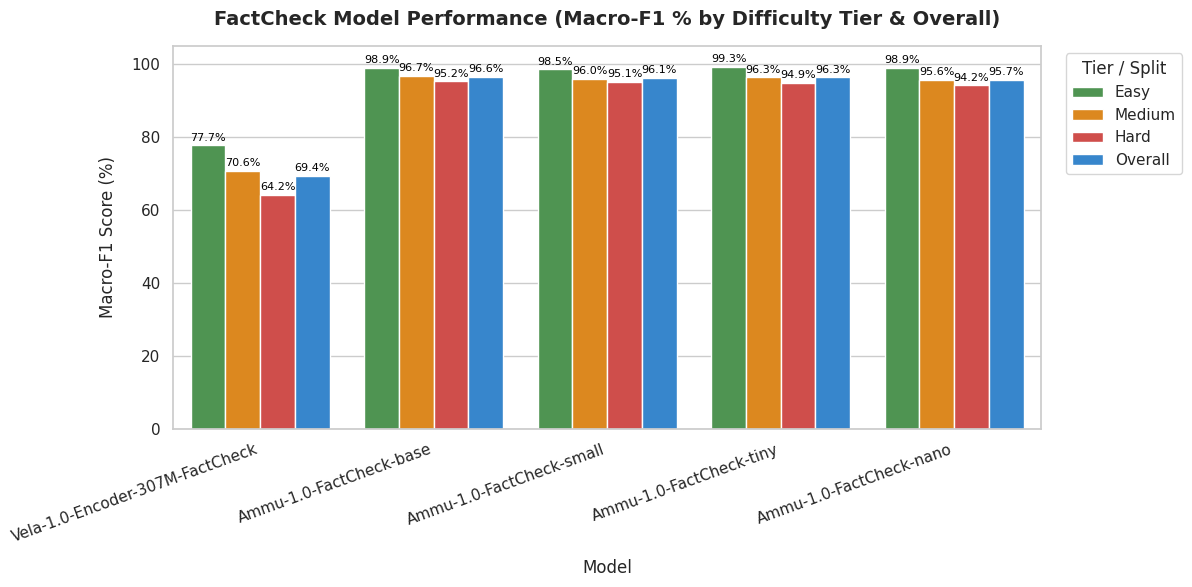

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "font.size": 11})

# Bar Plot: Macro-F1 Comparison across Tiers
plot_df = results_df.copy()
plot_df["Short_Name"] = plot_df["Model"].apply(lambda x: x.split("/")[-1])
melted_df = plot_df.melt(
    id_vars=["Short_Name", "Size"],
    value_vars=["Easy", "Medium", "Hard", "Overall"],
    var_name="Category",
    value_name="Macro_F1"
)

plt.figure(figsize=(12, 6))
palette = ["#43A047", "#FB8C00", "#E53935", "#1E88E5"]
ax = sns.barplot(
    data=melted_df,
    x="Short_Name",
    y="Macro_F1",
    hue="Category",
    palette=palette
)

plt.title("FactCheck Model Performance (Macro-F1 % by Difficulty Tier & Overall)", fontsize=14, weight="bold", pad=15)
plt.xlabel("Model", fontsize=12, labelpad=10)
plt.ylabel("Macro-F1 Score (%)", fontsize=12, labelpad=10)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Tier / Split", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.ylim(0, 105)

# Add values above bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%",
                    (p.get_x() + p.get_width() / 2., height),
                    ha="center", va="bottom",
                    fontsize=8, color="black",
                    xytext=(0, 2),
                    textcoords="offset points")

plt.tight_layout()
plt.show()


## 10. Save Evaluation Results
Export the benchmark results to CSV for persistent logging in Google Drive and local project directory.


In [10]:
# Save locally
results_csv_path = "fact_check_model_evaluation_results.csv"
results_df.to_csv(results_csv_path, index=False)
print(f"Results saved locally to: {results_csv_path}")

# Save to Google Drive output folder if accessible
drive_output_path = os.path.join(folder_path, "fact_check_model_evaluation_results.csv")
try:
    if os.path.exists(folder_path):
        results_df.to_csv(drive_output_path, index=False)
        print(f"Results saved to Google Drive: {drive_output_path}")
except Exception as e:
    print(f"Could not write to Google Drive: {e}")


Results saved locally to: fact_check_model_evaluation_results.csv
Results saved to Google Drive: /content/drive/MyDrive/Kalyan KS/Learning/Preparation Notes/Projects/Fact Check Need Classifier/fact_check_curated_output/fact_check_model_evaluation_results.csv
